# Estatística sobre o agente (AO1 da D3)

Parte escrita da AO1. Fica na pasta `D03/AO1/`, com o `ao1.py` e o arquivo de casos (`dados/casos-60.csv`).
Use o kernel do `.venv` do projeto e rode de cima para baixo. Onde houver **R:**, a resposta é minha.
Até as Decisões é a AO1; o que vem depois do E3 e do E4 é entregue com a N2.

Adaptado do notebook de apoio do professor (`apoio-professor/03-estatistica.ipynb`).

> **Escopo desta entrega:** itens 1 e 2 do enunciado. Por orientação do professor em aula (o PDF do enunciado aparece com esses pontos riscados), o intervalo de confiança por reamostragem, o cálculo de tamanho de amostra (item 3) e a página de correlação e causalidade (item 4) **ficam para a N2**. As seções correspondentes no fim deste notebook estão vazias de propósito.
>
> **Localização:** o enunciado cita `notebooks/03-estatistica.ipynb`. Mantive notebook, `ao1.py`, `acertos.csv` e casos juntos em `D03/AO1/`, a pasta da atividade, ao lado do enunciado.

- Conjunto: R: `dados/casos-60.csv`, com 60 casos rotulados por mim. Não usei o `casos-ams-60.csv` do pacote de apoio.
- De onde vieram os casos novos: R: os casos A01–A30 são os mesmos 30 casos reais do AI4I 2020 avaliados na D2 (`D02/D2-06-agente-baseline/adaptacao-ams/casos-lab-06-v2.csv`), adaptados ao esquema da D3 (`tipo_maquina` = família, `qualidade_produto` = L/M/H). Os casos B01–B30 são 30 casos novos do AI4I 2020, gerados por mim com um script pessoal (`extras-pessoal/scripts/gerador_casos.py`, que não vai na entrega): casos fáceis e difíceis, nenhum UDI repetido da D2, rótulos revisados por mim. A procedência completa está em `dados/FONTE.md`, e o de-para linha a linha em `dados/depara-60.csv`.
- A: linha de base da D2 (`decidir()` de `src/ams/baseline.py`). B: R: **passo de verificação antes de parar**. A A manda parar com uma única evidência de sensor (vibração > 7,0 mm/s ou desgaste ≥ 150 h); a primeira condição que casa decide. A B conta três evidências independentes de risco (vibração > 7,0 mm/s; desgaste ≥ 150 h; ao menos **uma** falha recente da mesma família) e decide pela confirmação:
  - 2 ou mais evidências → `parar_para_manutencao`;
  - 1 evidência → `inspecionar_antes_de_operar`;
  - nenhuma → `seguir_operando`.

  São **duas mudanças** em relação à A, ambas declaradas:
  1. **A regra de decisão (a principal):** confirmação por duas fontes no lugar de "a primeira condição que casa decide". É o exemplo "acrescentar um passo de verificação" do enunciado.
  2. **O corte do histórico:** a A só usa o histórico com 2 ou mais falhas recentes da família; a B conta o histórico como evidência já com 1. Sem isso, o histórico raramente somaria como segunda evidência.

  Os limiares de vibração e desgaste são os mesmos da A. "Inspecionar" aqui significa "não parar para manutenção", não "dispensar bloqueio": inspeção com acesso físico à máquina também exige LOTO (NR-12). A B é experimental, feita para a comparação; não foi adotada como agente.

In [1]:
%run ao1.py

60 casos
A acertou 35 · B acertou 26
decisões diferentes entre A e B: 26
discordam no A02 · A: 0 · B: 1
discordam no A03 · A: 1 · B: 0
discordam no A13 · A: 0 · B: 1
discordam no A14 · A: 1 · B: 0
discordam no A22 · A: 1 · B: 0
discordam no A24 · A: 1 · B: 0
discordam no A26 · A: 1 · B: 0
discordam no A29 · A: 1 · B: 0
discordam no B23 · A: 1 · B: 0
discordam no B13 · A: 1 · B: 0
discordam no B17 · A: 1 · B: 0
discordam no B02 · A: 1 · B: 0
discordam no B21 · A: 1 · B: 0
discordam no B19 · A: 1 · B: 0
discordam no B03 · A: 0 · B: 1
discordam no B11 · A: 1 · B: 0
discordam no B24 · A: 1 · B: 0
discordam no B07 · A: 0 · B: 1
discordam no B04 · A: 0 · B: 1
latência A (µs) em 3000 decisões: p50 0.8 · p95 1.6 · média 0.85 · máximo 53.7
latência B (µs) em 3000 decisões: p50 0.9 · p95 1.3 · média 0.93 · máximo 8.1


In [2]:
# Pareamento: os quatro quadrantes de acerto (A, B) sobre os MESMOS 60 casos
import pandas as pd

acertos = pd.read_csv(ARQUIVO_DE_ACERTOS)
print(pd.crosstab(acertos["linha_de_base"], acertos["variante_b"],
                  rownames=["A acertou"], colnames=["B acertou"], margins=True))

so_a = int(((acertos.linha_de_base == 1) & (acertos.variante_b == 0)).sum())
so_b = int(((acertos.linha_de_base == 0) & (acertos.variante_b == 1)).sum())
print(f"\nacerto geral: A = {acertos.linha_de_base.mean():.3f} · B = {acertos.variante_b.mean():.3f}")
print(f"discordantes: {so_a + so_b} (só A acertou: {so_a} · só B acertou: {so_b})")

# Em que tipo de caso a B muda a decisão da A
comparacao = pd.DataFrame({
    "id_caso": [c["id_caso"] for c in casos],
    "correta": [c["acao_correta"] for c in casos],
    "A": decisoes_a,
    "B": decisoes_b,
})
mudou = comparacao[comparacao.A != comparacao.B]
print(f"\ndecisões diferentes: {len(mudou)}")
print(pd.crosstab(mudou.A, mudou.B, rownames=["A decidiu"], colnames=["B decidiu"]))

# As 14 perdas da B (A acertou, B errou), separadas pelo que a A tinha decidido
perdas = comparacao[(comparacao.A == comparacao.correta) & (comparacao.B != comparacao.correta)]
print("\nperdas da B, pelo que a A decidiu (e acertou):")
for decisao_a, grupo in perdas.groupby("A"):
    print(f"  {decisao_a}: {len(grupo)} → {', '.join(grupo.id_caso)}")

# As métricas da §4 do agent-spec.md, para as duas variantes
PARAR, SEGUIR = "parar_para_manutencao", "seguir_operando"
reais_alto = (comparacao.correta == PARAR).sum()
linhas = {}
for nome in ["A", "B"]:
    d = comparacao[nome]
    linhas[nome] = {
        "acerto geral (primária)": f"{(d == comparacao.correta).sum()}/60",
        "recall alto (sec. 1, meta ≥ 80%)": f"{((d == PARAR) & (comparacao.correta == PARAR)).sum()}/{reais_alto}",
        "precisão alto (sec. 2, meta ≥ 80%)": f"{((d == PARAR) & (comparacao.correta == PARAR)).sum()}/{(d == PARAR).sum()}",
        "alto decidido como baixo (sec. 3, meta ≤ 5%)": f"{((d == SEGUIR) & (comparacao.correta == PARAR)).sum()}/{reais_alto}",
    }
print()
print(pd.DataFrame(linhas))

# Acerto da A por metade do conjunto (A01–A30 = casos da D2; B01–B30 = novos)
metade = comparacao.id_caso.str[0]
print("\nacerto por metade:")
print(pd.DataFrame({n: (comparacao[n] == comparacao.correta).groupby(metade).sum() for n in ["A", "B"]}))

B acertou   0   1  All
A acertou             
0          20   5   25
1          14  21   35
All        34  26   60

acerto geral: A = 0.583 · B = 0.433
discordantes: 19 (só A acertou: 14 · só B acertou: 5)

decisões diferentes: 26
B decidiu              inspecionar_antes_de_operar
A decidiu                                         
parar_para_manutencao                           16
seguir_operando                                 10

perdas da B, pelo que a A decidiu (e acertou):
  parar_para_manutencao: 8 → A03, A14, A22, A24, A29, B13, B02, B11
  seguir_operando: 6 → A26, B23, B17, B21, B19, B24

                                                  A      B
acerto geral (primária)                       35/60  26/60
recall alto (sec. 1, meta ≥ 80%)              10/16   2/16
precisão alto (sec. 2, meta ≥ 80%)            10/23    2/7
alto decidido como baixo (sec. 3, meta ≤ 5%)   5/16   1/16

acerto por metade:
          A   B
id_caso        
A        19  15
B        16  11


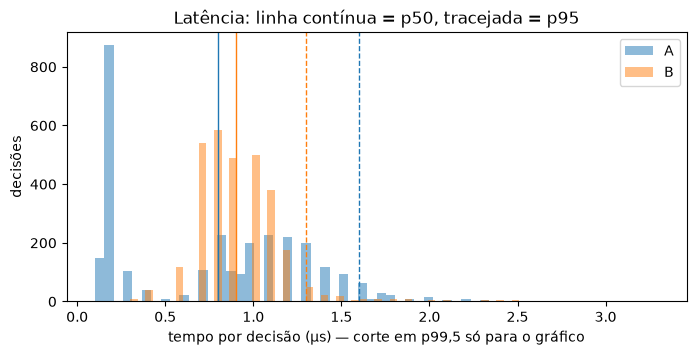

,A,B
p50,0.80,0.90
p95,1.60,1.30
média,0.85,0.93
máximo,53.70,8.10
média / p50,1.06,1.03


In [3]:
# Latência: distribuição dos tempos de decisão (50 rodadas × 60 casos por variante)
import matplotlib.pyplot as plt

fig, eixo = plt.subplots(figsize=(8, 3.5))
limite = np.percentile(np.concatenate([tempos_a, tempos_b]), 99.5)
for nome, t in [("A", tempos_a), ("B", tempos_b)]:
    eixo.hist(t[t <= limite], bins=60, alpha=0.5, label=nome)
    for q, estilo in [(50, "-"), (95, "--")]:
        eixo.axvline(np.percentile(t, q), linestyle=estilo, linewidth=1,
                     color="C0" if nome == "A" else "C1")
eixo.set_xlabel("tempo por decisão (µs) — corte em p99,5 só para o gráfico")
eixo.set_ylabel("decisões")
eixo.set_title("Latência: linha contínua = p50, tracejada = p95")
eixo.legend()
plt.show()

pd.DataFrame({nome: {"p50": np.percentile(t, 50), "p95": np.percentile(t, 95),
                     "média": t.mean(), "máximo": t.max(),
                     "média / p50": t.mean() / np.percentile(t, 50)}
              for nome, t in [("A", tempos_a), ("B", tempos_b)]}).round(2)

## As duas variantes e a latência

**Pareamento (acertos de cada variante, em quantos casos discordam e a favor de quem):** R: Sobre os mesmos 60 casos:
- **Acerto geral:** a A acerta **35/60 (58,3%)** e a B acerta **26/60 (43,3%)**.
- **Onde concordam e discordam:** as duas acertam juntas 21 casos e erram juntas 20. Os acertos discordam em **19 casos, 14 a favor da A e 5 a favor da B**. Em 26 casos as duas tomam decisões diferentes; em 7 deles as duas erram.
- **Direção das mudanças:** toda mudança da B vai para `inspecionar_antes_de_operar`. São 16 casos em que a A mandava parar e 10 em que mandava seguir. A B nunca cria uma parada nova.
- **Onde a B ganha (5):** nos casos em que a A parava com um sinal isolado e o rótulo era inspecionar (A02, A13, B03, B04, B07). É exatamente o que o passo de verificação devia corrigir.
- **Onde a B perde (14), por duas causas diferentes:**
  - **8 paradas rebaixadas.** São falhas reais com uma só evidência, que a A parava e a B mandou inspecionar (A03, A14, A22, A24, A29, B02, B11, B13). Vêm da mudança 1 (a confirmação).
  - **6 falsos alarmes.** São casos `seguir_operando` em que a única evidência era uma falha recente da família, e a B mandou inspecionar (A26, B17, B19, B21, B23, B24). Vêm da mudança 2 (o corte do histórico em 1).
- **As métricas da §4 do `agent-spec.md`** (tabela acima) mostram uma troca, não uma piora em tudo:
  - **Recall da classe "alto":** cai de **10/16 na A para 2/16 na B**.
  - **Precisão da classe "alto":** vai de 10/23 para 2/7.
  - **Casos "alto" decididos como "baixo":** a secundária 3, que a §6 chama de "o erro mais caro do domínio", **melhora de 5/16 (31%) na A para 1/16 (6%) na B**. A B rebaixa os casos graves para inspecionar, não para seguir: quase nenhuma máquina de risco real fica operando sem que ninguém olhe para ela. Em compensação, ela quase não manda parar.

  **Nenhuma das duas atinge a §4.** A A falha no recall (62,5% contra a meta de 80%), na precisão (43%) e na secundária 3 (31% contra a meta de no máximo 5%). A B falha no recall e na precisão e passa perto do limite na secundária 3 (6%).
- **O que 60 casos permitem afirmar:** a diferença bruta de acerto geral é de 15 pontos percentuais. Com 19 discordantes (14 contra 5), se ela é distinguível do acaso depende do teste pareado sobre os discordantes. Esse teste é do D3-06 e entra na N2; até lá, a leitura honesta é "não sei ainda".
- **Ressalvas de desenho (as duas variantes):**
  - **A B** foi pensada olhando os erros da A nestes mesmos 60 casos.
  - **Os limiares da A** foram calibrados na D2 sobre os casos A01–A30, que estão aqui dentro.

  As duas leituras de acerto, portanto, tendem a ser otimistas nessa metade do conjunto. A metade B01–B30 é a única que nenhuma das duas viu durante o desenho (a A acerta 16/30 nela).
- **Por que a A acerta 19/30 em A01–A30 e não 21/30 como na D2:** os limiares e as leituras são os mesmos. O que mudou foi `tipo_maquina`, que na adaptação ao esquema da D3 passou a ser uma família sorteada (seed 99, ver `dados/FONTE.md`). Como o `EstadoDaFrota` conta falhas recentes **por família**, o agrupamento novo fez a A mandar inspecionar em dois casos que eram `seguir_operando`, A15 e A21. Conferi isso rodando `baseline.medir()` nos dois arquivos: as listas de erros diferem só nesses dois casos.

**Latência (p50 e p95, e por que a média engana em tempo de resposta):** R: Foram 3.000 decisões por variante (50 passadas × 60 casos). Os valores exatos estão na tabela acima e **mudam a cada execução**, com a carga da máquina.
- **Ordem de grandeza (estável):** p50 e p95 ficam na casa de 1 µs a poucos µs. O máximo fica várias vezes acima do p50.
- **A versus B:** as diferenças entre as duas variantes são de décimos de microssegundo. Isso está no nível da resolução do `time.perf_counter` no Windows (cerca de 0,1 µs), então nenhuma das duas é "mais rápida" de forma confiável. Na operação, ambas são instantâneas.

Tempo de resposta não tem distribuição simétrica. Ele tem piso, porque nenhuma decisão é mais rápida que o custo mínimo da função. E tem cauda longa à direita: interrupções do sistema operacional, coleta de lixo do Python, cache frio na primeira passada e, no agente com LLM, rede e fila do provedor. Poucas chamadas muito lentas puxam a média para cima. Com isso, a média deixa de descrever a chamada típica e também não mostra quão ruim é o pior caso frequente. O p50 diz quanto demora uma decisão comum. O p95 diz o tempo que 1 em cada 20 invocações ultrapassa, que é o atraso que o técnico realmente sente.

Ressalva honesta: neste agente de regras a distribuição é tão estreita que a média quase coincide com o p50 (razão média/p50 perto de 1). Aqui o efeito da cauda aparece no máximo, não na média. O argumento contra a média vale com força total para o agente baseado em LLM (D10), cujas chamadas levam segundos e têm cauda longa de rede. Por isso o relatório já adota p50 e p95 desde a linha de base.

In [4]:
# O medidas.py só protege as decisões escritas quando a saída se chama
# relatorio-dado.md; com --saida relatorio-60.md ele SOBRESCREVE. Por isso só
# gera o relatório se ele ainda não existir; as decisões ficam preservadas.
import sys
from pathlib import Path
if not Path("relatorio-60.md").exists():
    !"{sys.executable}" ../D3-03-estatistica-descritiva/medidas.py dados/casos-60.csv --saida relatorio-60.md
from IPython.display import Markdown
Markdown(open("relatorio-60.md", encoding="utf-8").read())

# O meu dado, com rigor — relatório do Laboratório 03

Conjunto: `dados\casos-60.csv` · 60 linhas · 11 variáveis

Medidas geradas pelo `medidas.py`: desvio padrão amostral (ddof=1),
quartis por interpolação linear, extremos pela regra da amplitude
interquartil — fora de 1,5 × a caixa (slide 24). As medidas são do
programa; as decisões são SUAS. Preencha todos os blocos `R:` e
confira com `python teste.py`.

## Medidas por variável

| variável | tipo | n | faltantes | média | mediana | desvio | Q1 | Q3 | AIQ | mín | máx |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| id_caso | categórica (60 valores; moda: B30) | 60 | 0 | — | — | — | — | — | — | — | — |
| data | categórica (60 valores; moda: 2026-04-01) | 60 | 0 | — | — | — | — | — | — | — | — |
| tipo_maquina | categórica (4 valores; moda: ROBOT) | 60 | 0 | — | — | — | — | — | — | — | — |
| qualidade_produto | categórica (3 valores; moda: L) | 60 | 0 | — | — | — | — | — | — | — | — |
| temperatura_c | numérica | 60 | 0 | 36.7033 | 36.8500 | 1.5445 | 35.4250 | 37.8250 | 2.4000 | 33.4000 | 39.9000 |
| vibracao_mm_s | numérica | 60 | 0 | 3.8367 | 3.4000 | 1.9182 | 2.4750 | 4.5000 | 2.0250 | 2.1000 | 11.3000 |
| horas_desde_manutencao | numérica | 60 | 0 | 110.1833 | 100.0000 | 70.1771 | 52.2500 | 170.7500 | 118.5000 | 0.0000 | 240.0000 |
| acao_correta | categórica (3 valores; moda: seguir_operando) | 60 | 0 | — | — | — | — | — | — | — | — |
| falhou_depois | numérica | 60 | 0 | 0.2667 | 0.0000 | 0.4459 | 0.0000 | 1.0000 | 1.0000 | 0.0000 | 1.0000 |
| risco | categórica (3 valores; moda: baixo) | 60 | 0 | — | — | — | — | — | — | — | — |
| dificuldade | categórica (3 valores; moda: facil) | 60 | 0 | — | — | — | — | — | — | — | — |

## Extremos marcados (fora de 1,5 × a caixa — slide 24)

### Extremos de `vibracao_mm_s` — 4 valor(es), limites [-0.5625; 7.5375]

| linha | valor |
|---:|---:|
| 8 | 9.2000 |
| 14 | 11.3000 |
| 34 | 9.7000 |
| 41 | 9.7000 |

Decisão sobre ESTES extremos — manter ou remover, caso a caso,
com o motivo (slide 25: quem remove sem dizer, mente por omissão):

R: Manter os 4, caso a caso. A08 (9,2 mm/s; inspecionar, difícil) e B04 (9,7; inspecionar, difícil) são casos em que vibração alta sozinha não justificava parar. Estão no conjunto justamente para testar se o agente distingue sinal isolado de risco confirmado. A14 (11,3; parar, falhou) e B11 (9,7; parar, falhou) são falhas reais. Nenhum é erro de digitação: `vibracao_mm_s` é um proxy calculado pela mesma fórmula sobre RPM e torque reais do AI4I (`NOTA-vibracao-mm-s.md` da D2). O extremo reflete RPM e torque longe da mediana, coerente com a curva de potência vista na D1. Se fossem removidos: n cairia para 56, a média de vibração de 3,84 para 3,40, a mediana de 3,40 para 3,35, e a classe parar perderia 2 dos seus 16 casos. A comparação A×B perderia justamente os casos que mais distinguem as variantes.


## Faltantes (os três mecanismos do slide 26)

Nenhuma variável tem valores faltantes.

## As quatro perguntas do slide 29

**1. Média e mediana se separam em alguma variável? Em qual?**

R: Sim, em `vibracao_mm_s`: média 3,84 contra mediana 3,40, uma diferença de 0,44 mm/s (cerca de 13% da mediana; assimetria ≈ 2,3), puxada pelos 4 extremos. Sem eles, a média fica em 3,40 e a mediana em 3,35. Nas outras numéricas as duas ficam próximas: `temperatura_c` 36,70 × 36,85 e `horas_desde_manutencao` 110,2 × 100,0 (10 h de diferença numa AIQ de 118,5, sem extremos). Em `falhou_depois`, a média 0,27 é a proporção de falhas (16/60), e a mediana 0 só diz que a maioria não falhou.

**2. Quantos extremos foram marcados, e quantos você decidiu manter?**

R: 4 extremos marcados, todos em `vibracao_mm_s`: linhas 8, 14, 34 e 41, que são os casos A08, A14, B04 e B11. Mantive os 4. Diferente do Lab 03, aqui `falhou_depois` não gera extremos. Com 16/60 = 27% de falhas, Q3 = 1 e a caixa cobre o 0 e o 1. Na amostra do Lab 03 a falha era rara (4%), então todo 1 caía fora da caixa por construção da regra.

**3. Algum faltante parece do terceiro mecanismo?**

R: Não. Há 0 faltantes nas 11 colunas, porque o conjunto foi montado a partir de linhas completas do AI4I, que não tem faltantes: os 30 casos da D2 adaptados e os 30 do gerador. Numa operação real, o candidato ao terceiro mecanismo (perdido por causa do próprio valor) seria uma leitura de sensor não registrada justamente porque a máquina estava parada ou com defeito. Isso proibiria descartar as linhas incompletas. A descrição textual da OS, que a §2 do `agent-spec.md` lista entre as entradas do agente, não existe no conjunto de avaliação. É uma lacuna por desenho do conjunto, não uma célula faltante.

**4. O que a análise da D1 não tinha visto?**

R: Três coisas. (1) O balanceamento do conjunto de avaliação. A D1 olhou a base inteira, com cerca de 3,4% de falhas. Aqui os casos foram escolhidos: a classe parar tem 16/60 (27%) e seguir tem 32/60 (53%). Um agente que sempre mandasse seguir acertaria 53%. A D1 não precisava considerar esse piso, e ele relativiza os 58% da linha de base. (2) `falhou_depois` coincide 100% com `acao_correta` = parar: vale 1 em 16 de 16 casos e 0 em todos os outros. O rótulo foi derivado do desfecho, então `falhou_depois` não pode ser entrada do agente; só realimenta o `EstadoDaFrota` depois da decisão. (3) Os extremos agora aparecem numa variável derivada (`vibracao_mm_s`, proxy de RPM e torque), não nas medidas brutas. A D1 viu os extremos de rotação; aqui eles reaparecem transformados, e metade deles (2 de 4) são casos difíceis rotulados inspecionar, não falhas.

## Comparação com a análise exploratória da D1

O que mudou de lá para cá — o que a análise de lá não tinha visto,
e o que estas decisões escritas mudam no conjunto que a D5 vai usar:

R: O conjunto que importa para avaliar o agente não é a base da D1 (10.000 linhas), e sim estes 60 casos escolhidos, com outra estrutura: classes desbalanceadas a favor de seguir (53%), falhas super-representadas (27%, contra cerca de 3,4% na base) e 16 casos difíceis ou atípicos de propósito. Isso muda duas coisas daqui em diante. O acerto geral (métrica primária) precisa vir sempre acompanhado do recall da classe alto e do piso trivial de 53%. E qualquer comparação entre variantes precisa usar estes mesmos 60 casos, pareados. As decisões escritas aqui não alteram o conjunto: nenhuma remoção e nenhuma imputação. O `acertos.csv` e o notebook usam os 60 casos exatamente como estão em `dados/casos-60.csv`.


## Decisões

**Distribuições das variáveis relevantes:** R: O conjunto tem 60 casos sem faltantes.
- **Classes de `acao_correta`:** `seguir_operando` 32, `parar_para_manutencao` 16, `inspecionar_antes_de_operar` 12. O conjunto é desbalanceado, e isso dá contexto ao acerto geral: um agente que sempre respondesse "seguir" acertaria 32/60 = 53%. Os 58% da A estão só 5 pp acima desse piso trivial, e os 43% da B ficam abaixo dele. Por isso a métrica primária não pode ser lida sem o recall da classe "alto" ao lado.
- **`falhou_depois`:** vale 1 exatamente nos 16 casos `parar_para_manutencao` e 0 em todos os outros. Não é uma variável independente: é o desfecho que gerou o rótulo, e o agente só o conhece depois da decisão (alimenta o `EstadoDaFrota`). Não pode entrar como entrada da regra.
- **`temperatura_c`:** é a temperatura de processo do AI4I convertida de K para °C. É simétrica (média 36,70 ≈ mediana 36,85; assimetria ≈ −0,05) e estreita (33,4 a 39,9 °C, desvio de 1,54). Não tem extremos e quase não separa as classes, o que é coerente com a decisão da D2 de não usá-la na regra.
- **`vibracao_mm_s`:** é um proxy derivado de RPM e torque (não é um sensor real; ver `NOTA-vibracao-mm-s.md` na D2). É a única variável assimétrica à direita: média 3,84 > mediana 3,40, assimetria ≈ 2,3. A separação entre média e mediana vem dos quatro extremos.
- **`horas_desde_manutencao`:** é o desgaste da ferramenta, o gatilho do modo TWF. Espalha-se por toda a faixa de 0 a 240 h (média 110 ≈ mediana 100, AIQ de 118) e não tem extremos.
- **Categóricas:** `tipo_maquina` tem ROBOT 18, PRENSA 17, COMPRESSOR 16 e TORNO 9. `qualidade_produto` tem L 32, M 17 e H 11, a mesma predominância de L do AI4I. `dificuldade` tem 44 fáceis, 12 difíceis e 4 atípicos. A presença de casos difíceis e atípicos foi intencional ("casos fáceis e difíceis, não só os óbvios").

**Extremos (para cada variável: ficam ou saem, por quê, e o que muda):** R: Só `vibracao_mm_s` tem extremos pela regra de 1,5 × AIQ: 4 valores acima de 7,54 mm/s.
- **A08** (9,2): inspecionar, difícil.
- **A14** (11,3): parar, falhou.
- **B04** (9,7): inspecionar, difícil.
- **B11** (9,7): parar, falhou.

**Ficam todos.** Não são erros de medição: saem da mesma fórmula, aplicada a RPM e torque reais do AI4I. E são exatamente os casos que a regra de vibração da A (limiar de 7,0) existe para tratar. Dois são falhas reais e dois são casos difíceis em que vibração alta não justificava parar. Removê-los tiraria do conjunto os casos que mais distinguem as variantes, e a avaliação ficaria mais fácil do que a realidade.

O que mudaria se saíssem: n cai para 56; a média de vibração cai de 3,84 para 3,40 e a mediana quase não se move (3,40 para 3,35), o que mostra que a mediana é a medida robusta aqui. Também sairiam 2 dos 16 casos "parar", deixando a classe grave ainda menor.

Nas outras variáveis numéricas (temperatura, horas) não há extremos a decidir. `falhou_depois` é binária, então a regra da caixa não se aplica.

**Faltantes (o mecanismo provável: perdido ao acaso, perdido condicionalmente ou perdido por causa do próprio valor, e o que ele autoriza; ou "não há"):** R: **Não há**: zero células faltantes nas 11 colunas. A ausência vem da construção. O AI4I 2020 não tem faltantes, e os 60 casos foram montados por mim a partir de linhas completas (os 30 da D2 e os 30 do gerador). Sem faltantes, não há imputação nem exclusão a justificar, e nenhum mecanismo precisa ser suposto.

Registro, para quando o AMS receber ordens de serviço reais: o faltante mais provável ali seria do terceiro mecanismo, perdido por causa do próprio valor (MNAR). Por exemplo, uma leitura de sensor que não foi registrada justamente porque a máquina estava parada ou com defeito. Esse mecanismo **proíbe** descartar as linhas incompletas, porque elas não são uma amostra ao acaso dos casos (seriam desproporcionalmente as graves). Exigiria tratar "sem leitura" como informação.

Há também uma lacuna estrutural: a §2 do `agent-spec.md` lista os dados da ordem de serviço entre as entradas do agente, mas o conjunto de avaliação não traz a descrição textual da OS, só as leituras e o histórico. É uma variável ausente por desenho do conjunto, não uma célula faltante, e reforça a observabilidade parcial declarada na §2.

## Intervalo por reamostragem (depois do E3, entregue com a N2)

## Tamanho de amostra (depois do E3, entregue com a N2)

## Correlação e causalidade (depois do E4, entregue com a N2)

## Comparação pareada (depois do E4, anexo da N2)